# Initial Stuff

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



# Analysis

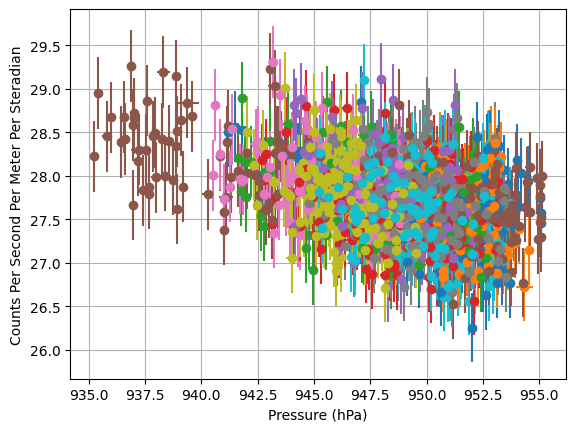

Slope: -0.193529 +/- 0.011862
Total Days: 54.591536


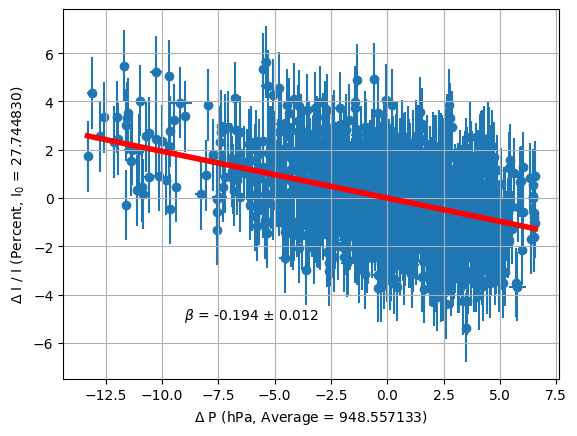

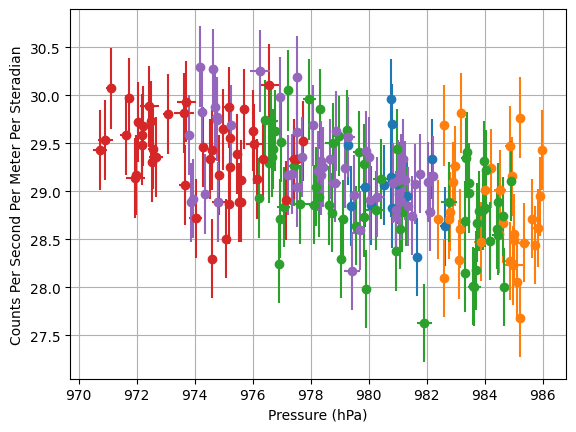

Slope: -0.239466 +/- 0.026356
Total Days: 8.877075


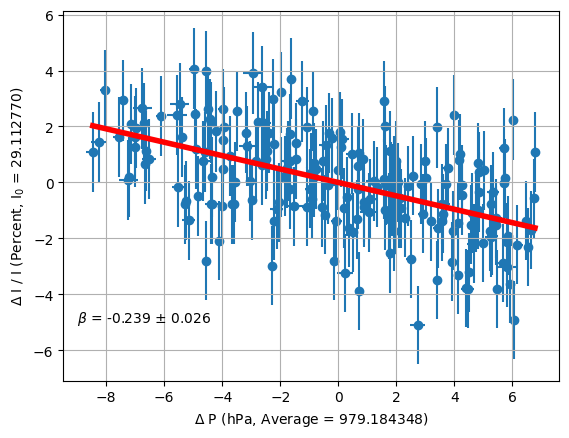

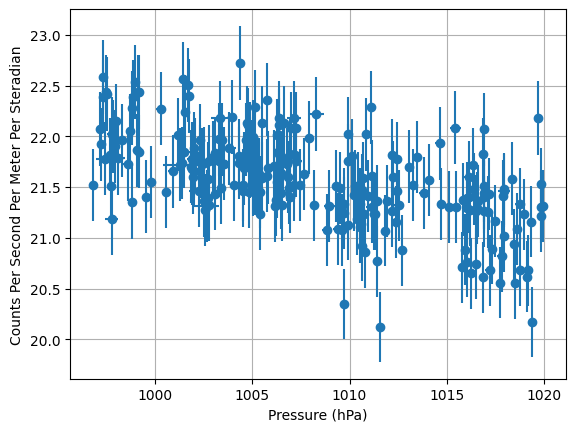

Slope: -0.192505 +/- 0.017031
Total Days: 9.998570


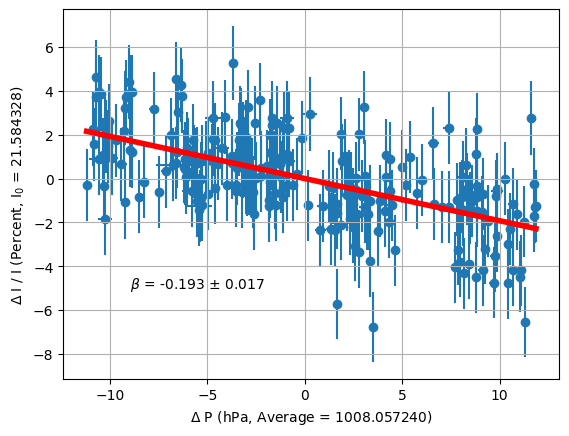

In [8]:
####
#### function to get pressure and rate
####
def getCntsPress(fname,_BINTIME_):
  ## read in values from file
  secs,utcsec,aamp,bamp,temp,press = np.genfromtxt(fname,delimiter=',',usecols=(2,3,4,5,6,7),skip_header=1,unpack=True)

  ## how many days
  daysInFile = (utcsec[-1]-utcsec[0])/3600./24.
  #print((utcsec[-1]-utcsec[0])/3600./24.)

  ## binning info
  _LENGTH_ = (utcsec[-1]-utcsec[0])
  _NBINS_ = int(_LENGTH_/_BINTIME_) + 1

  ## create histogram of counts in time
  cnts, edges = np.histogram(utcsec,np.arange(utcsec[0],utcsec[-1]+_BINTIME_,_BINTIME_))
  cnts = cnts[:-1] # <- get rid of last bin, which will have dead time
  cerr = np.sqrt(cnts)

  ## get pressure values in each time bin
  prvs = np.zeros(len(cnts))
  prve = np.zeros(len(cnts))
  for i in range(len(cnts)):
    mask = (utcsec>=edges[i]) & (utcsec<edges[i+1])
    prvs[i] = np.average(press[mask])
    prve[i] = np.std(press[mask])

  ## return value arrays
  return cnts,cerr,prvs,prve,daysInFile


## binning size in seconds
_BINTIME_ = 3600.*1.
## put the count rate in the correct units
FACTOR = _BINTIME_*225./10000.*2.094 # <- account for detector area (225/10,000) and acceptance angle (2.094 steradians)

## file numbers
fnums = ['1','3','4','6','7','8','9','10','11','12','13','14','15']
## variables to store all files
allx = np.zeros(0)
ally = np.zeros(0)
allxerr = np.zeros(0)
allyerr = np.zeros(0)
totalDays = 0.
## loop through files
for num in fnums:
  fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/PressureData-%s.csv'%(num)
  ## get data
  cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
  totalDays += days

  ## plot this file
  plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
  ## save all results in one place
  allx = np.append(allx,prvs)
  ally = np.append(ally,cnts/FACTOR)
  allxerr = np.append(allxerr,prve)
  allyerr = np.append(allyerr,cerr/FACTOR)

lnums = ['1','3','4']
for num in lnums:
  fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/PD-%s.csv'%(num)
  ## get data
  cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
  totalDays += days

  ## plot this file
  plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
  ## save all results in one place
  allx = np.append(allx,prvs)
  ally = np.append(ally,cnts/FACTOR)
  allxerr = np.append(allxerr,prve)
  allyerr = np.append(allyerr,cerr/FACTOR)

gndNums = ['1','2','3','4']
for num in gndNums:
  fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/CoordGrndTest/TX/CoordGrndTest-%s.csv'%(num)
  cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
  totalDays += days

  ## plot this file
  plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
  ## save all results in one place
  allx = np.append(allx,prvs)
  ally = np.append(ally,cnts/FACTOR)
  allxerr = np.append(allxerr,prve)
  allyerr = np.append(allyerr,cerr/FACTOR)

## finish plot
plt.xlabel("Pressure (hPa)")
plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.grid()
plt.show()

## find average and create plotting variables
avecnts = np.average(ally)
pltx = allx - np.average(allx)
plty = (ally-avecnts)/avecnts*100.
pltxerr = allxerr
pltyerr = allyerr/avecnts*100.
#intercept, slope = np.polynomial.Polynomial.fit(pltx, plty, 1).convert().coef
#print(intercept,slope)

## calculate slope and its error
m = np.sum(pltx * plty) / np.sum(pltx**2)
residuals = plty - m * pltx
n = len(pltx)
dof = n - 1
residual_variance = np.sum(residuals**2) / dof
merr = np.sqrt(residual_variance / np.sum(pltx**2))
print("Slope: %f +/- %f"%(m,merr))
print("Total Days: %f"%(totalDays))

xvals = np.arange(np.min(pltx),np.max(pltx),0.01)
#yvals = intercept + slope*xvals
yvals = m*xvals

plt.errorbar(pltx,plty,yerr=pltyerr,xerr=pltxerr,fmt='o',zorder=1)
plt.plot(xvals,yvals,'r-',lw=4,zorder=2)

# gndNames = ['CoordGrndTest-1.csv','CoordGrndTest-2.csv','July_22_2026_2.csv']
# colorNames = ['green','green','black']
# for gndName,col in zip(gndNames,colorNames):
#   fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/CoordGrndTest/%s'%(gndName)
#   cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
#   cnts = cnts/FACTOR
#   cerr = cerr/FACTOR
#   px = prvs - np.average(prvs)
#   avec = np.average(cnts)
#   py = (cnts-avec)/avec*100.
#   #plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
#   plt.errorbar(px,py,yerr=cerr/avec*100.,xerr=prve,fmt='o',color=col)

plt.xlabel(r"$\Delta$ P (hPa, Average = %f)"%(np.average(allx)))
#plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.ylabel(r"$\Delta$ I / I (Percent, I$_0$ = %f)"%(avecnts))
plt.text(-9.,-5.,r"$\beta$ = %.3f $\pm$ %.3f"%(m,merr))
plt.grid()
plt.show()


#### SC Data
## variables to store all files
SCallx = np.zeros(0)
SCally = np.zeros(0)
SCallxerr = np.zeros(0)
SCallyerr = np.zeros(0)
SCtotalDays = 0.
fnames = ['22_2026_2','23_2026_1','24_2026_1','27_2026_1','29_2026_1']
for nam in fnames:
  fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/CoordGrndTest/SC/mDetect_July_%s.csv'%(nam)
  cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
  SCtotalDays += days

  ## plot this file
  plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
  ## save all results in one place
  SCallx = np.append(SCallx,prvs)
  SCally = np.append(SCally,cnts/FACTOR)
  SCallxerr = np.append(SCallxerr,prve)
  SCallyerr = np.append(SCallyerr,cerr/FACTOR)

## finish plot
plt.xlabel("Pressure (hPa)")
plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.grid()
plt.show()


## find average and create plotting variables
avecnts = np.average(SCally)
pltx = SCallx - np.average(SCallx)
plty = (SCally-avecnts)/avecnts*100.
pltxerr = SCallxerr
pltyerr = SCallyerr/avecnts*100.
#intercept, slope = np.polynomial.Polynomial.fit(pltx, plty, 1).convert().coef
#print(intercept,slope)

## calculate slope and its error
m = np.sum(pltx * plty) / np.sum(pltx**2)
residuals = plty - m * pltx
n = len(pltx)
dof = n - 1
residual_variance = np.sum(residuals**2) / dof
merr = np.sqrt(residual_variance / np.sum(pltx**2))
print("Slope: %f +/- %f"%(m,merr))
print("Total Days: %f"%(SCtotalDays))

xvals = np.arange(np.min(pltx),np.max(pltx),0.01)
#yvals = intercept + slope*xvals
yvals = m*xvals

plt.errorbar(pltx,plty,yerr=pltyerr,xerr=pltxerr,fmt='o',zorder=1)
plt.plot(xvals,yvals,'r-',lw=4,zorder=2)

plt.xlabel(r"$\Delta$ P (hPa, Average = %f)"%(np.average(SCallx)))
#plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.ylabel(r"$\Delta$ I / I (Percent, I$_0$ = %f)"%(avecnts))
plt.text(-9.,-5.,r"$\beta$ = %.3f $\pm$ %.3f"%(m,merr))
plt.grid()
plt.show()




#### PA Data
## variables to store all files
PAallx = np.zeros(0)
PAally = np.zeros(0)
PAallxerr = np.zeros(0)
PAallyerr = np.zeros(0)
PAtotalDays = 0.
fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/CoordGrndTest/PA/datafile.csv'
cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
PAtotalDays += days

## plot this file
plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
## save all results in one place
PAallx = np.append(PAallx,prvs)
PAally = np.append(PAally,cnts/FACTOR)
PAallxerr = np.append(PAallxerr,prve)
PAallyerr = np.append(PAallyerr,cerr/FACTOR)

## finish plot
plt.xlabel("Pressure (hPa)")
plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.grid()
plt.show()


## find average and create plotting variables
avecnts = np.average(PAally)
pltx = PAallx - np.average(PAallx)
plty = (PAally-avecnts)/avecnts*100.
pltxerr = PAallxerr
pltyerr = PAallyerr/avecnts*100.
#intercept, slope = np.polynomial.Polynomial.fit(pltx, plty, 1).convert().coef
#print(intercept,slope)

## calculate slope and its error
m = np.sum(pltx * plty) / np.sum(pltx**2)
residuals = plty - m * pltx
n = len(pltx)
dof = n - 1
residual_variance = np.sum(residuals**2) / dof
merr = np.sqrt(residual_variance / np.sum(pltx**2))
print("Slope: %f +/- %f"%(m,merr))
print("Total Days: %f"%(PAtotalDays))

xvals = np.arange(np.min(pltx),np.max(pltx),0.01)
#yvals = intercept + slope*xvals
yvals = m*xvals

plt.errorbar(pltx,plty,yerr=pltyerr,xerr=pltxerr,fmt='o',zorder=1)
plt.plot(xvals,yvals,'r-',lw=4,zorder=2)

plt.xlabel(r"$\Delta$ P (hPa, Average = %f)"%(np.average(PAallx)))
#plt.ylabel("Counts Per Second Per Meter Per Steradian")
plt.ylabel(r"$\Delta$ I / I (Percent, I$_0$ = %f)"%(avecnts))
plt.text(-9.,-5.,r"$\beta$ = %.3f $\pm$ %.3f"%(m,merr))
plt.grid()
plt.show()


# gndNames = ['CoordGrndTest-1.csv','CoordGrndTest-2.csv','July_22_2026_2.csv']
# colorNames = ['green','green','black']
# for gndName,col in zip(gndNames,colorNames):
#   fname = '/content/drive/MyDrive/Research/Students/HERA/Pressure Analysis/CoordGrndTest/%s'%(gndName)
#   cnts,cerr,prvs,prve,days = getCntsPress(fname,_BINTIME_)
#   cnts = cnts/FACTOR
#   cerr = cerr/FACTOR
#   px = prvs - np.average(prvs)
#   avec = np.average(cnts)
#   py = (cnts-avec)/avec*100.
#   #plt.errorbar(prvs,cnts/FACTOR,yerr=cerr/FACTOR,xerr=prve,fmt='o')
#   plt.errorbar(px,py,yerr=cerr/avec*100.,xerr=prve,fmt='o',color=col)
# plt.grid()
# plt.show()